In [8]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

import pandas as pd
from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures')

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255



In [2]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

## Handtune

In [3]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

In [4]:
from hnn_core import read_params

hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'default_human_ET.json')
params = read_params(params_fname)

In [10]:

from optimize_drives_slurm import set_params, set_params_time

with open('optim_drives_1000.pkl', 'rb') as file:
        optim_drives = pickle.load(file)

with open('optim_time_scale_1000.pkl', 'rb') as file:
        optim = pickle.load(file)

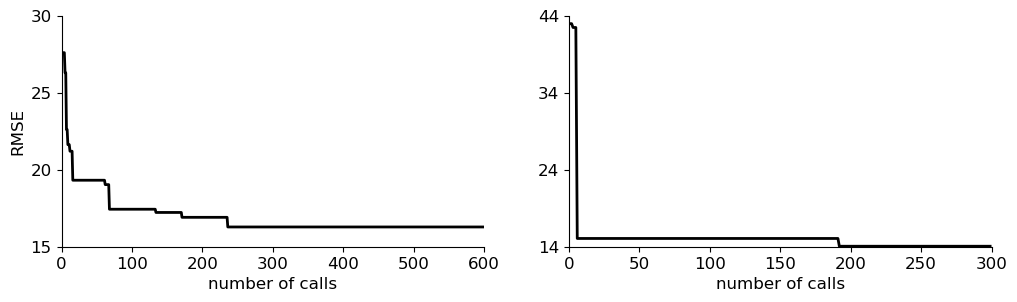

In [11]:
fig, ax = plt.subplots(1,2,figsize=(12,3))
ax[0].plot(np.arange(len(optim_drives.obj_)), optim_drives.obj_, color='k', linewidth=2)
ax[0].set_ylabel('RMSE')
ax[0].set_xlabel('number of calls')
ax[0].set_ylim([15, 30])
ax[0].set_yticks(np.arange(15, 31, 5))
ax[0].spines['right'].set_visible(False)
ax[0].spines['top'].set_visible(False)
ax[0].set_xlim([0, 600])
ax[1].plot(np.arange(len(optim.obj_)), optim.obj_, color='k', linewidth=2)
ax[1].set_xlabel('number of calls')
ax[1].set_ylim([14, 44])
ax[1].set_yticks(np.arange(14, 45, 10))
ax[1].spines['right'].set_visible(False)
ax[1].spines['top'].set_visible(False)
ax[1].set_xlim([0, 300])

fig.savefig(os.path.join(pathfig, 'bayes_convergence.pdf'), dpi=300)



## Import optimized parameters 

In [12]:
from optimize_drives_slurm import set_params, set_params_time
import pickle

with open('optim_time_scale_1000.pkl', 'rb') as file:
        optim = pickle.load(file)

with open('dpl_time_1000.pkl', 'rb') as file:
        dpl_opt = pickle.load(file)

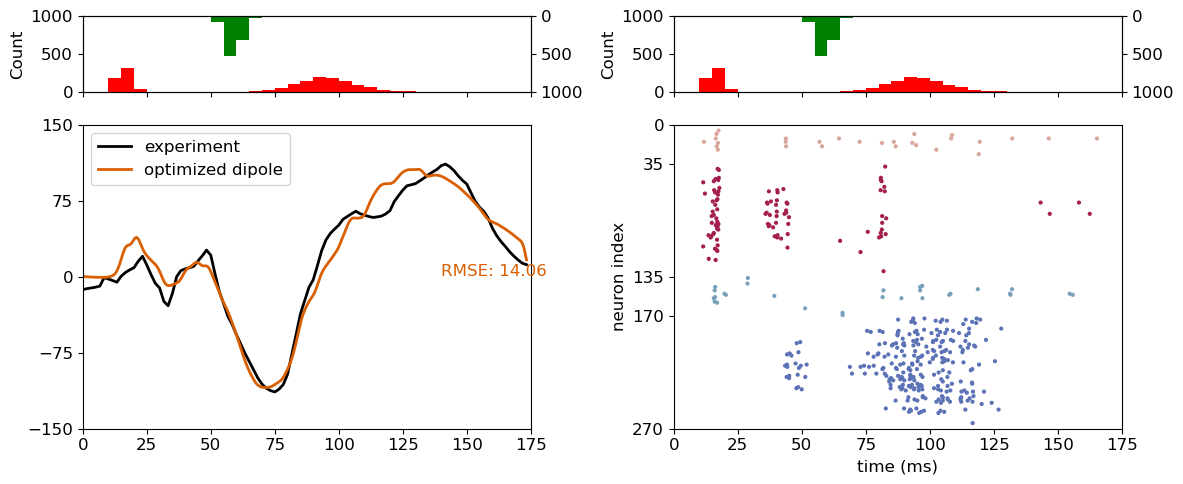

In [14]:
fig, ax = plt.subplots(2, 2,figsize=(12,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(optim.net_.cell_response.spike_times_by_type['prox1']).reshape(-1,1)
spike_dist = np.array(optim.net_.cell_response.spike_times_by_type['dist']).reshape(-1,1)
spike_prox2 = np.array(optim.net_.cell_response.spike_times_by_type['prox2']).reshape(-1,1)


for i in range(2):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1, 0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])
ax[1, 0].text(140, 0.5, 'RMSE: %.2f' % _rmse(dpl_opt, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[1])
ax[1, 0].legend()

# spiking
I = np.array(optim.net_.cell_response.spike_gids[0]) <270
gids = np.array(optim.net_.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(optim.net_.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(optim.net_, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=4, alpha=1., c=colors)
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'erp_spiking.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_spiking.pdf'), dpi=300)



In [10]:
l23_spiker = [gid for gid in optim.net_.cell_response.spike_gids[0] if gid in optim.net_.gid_ranges['L2_pyramidal']]
l5_spiker = [gid for gid in optim.net_.cell_response.spike_gids[0] if gid in optim.net_.gid_ranges['L5_pyramidal']]

l23_ca_apical_1 = np.zeros((100, len(optim.net_.cell_response.ca[0][35]['soma'])))
for g, gid in enumerate(optim.net_.gid_ranges['L2_pyramidal']):
    l23_ca_apical_1[g] = optim.net_.cell_response.ca[0][gid]['apical_1']

l5_ca_apical_1 = np.zeros((100, len(optim.net_.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(optim.net_.gid_ranges['L5_pyramidal']):
    l5_ca_apical_1[g] = optim.net_.cell_response.ca[0][gid]['apical_tuft']

fig, ax = plt.subplots(3,2,figsize=(12,7), height_ratios=[0.25,1, 0.5], sharex=True, constrained_layout=True)

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1000])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

im = ax[1,0].pcolormesh(optim.net_.cell_response.times, np.arange(100), l23_ca_apical_1, shading='gouraud', vmin=5e-5, vmax=0.0015, rasterized=True)
ax[1,0].set_ylim([0, 100])
ax[1,0].set_yticks(np.arange(0, 101, 25))
ax[1,0].spines['top'].set_visible(False)
ax[1,0].set_ylabel('L2 neuron idx')

ax10tw = ax[1,0].twinx()
ax10tw.plot(opt_dpl.times, opt_dpl.data['L2'], color='w')
ax10tw.spines['top'].set_visible(False)
ax10tw.set_ylabel('L2 dipole (nA $\cdot$ 1,000)')

cb = plt.colorbar(im, ax=ax[1,0], orientation='horizontal', shrink=0.5)
cb.set_ticks([5e-5, 0.0015])
cb.set_label('apical calcium (mM)')


im = ax[1,1].pcolormesh(optim.net_.cell_response.times, np.arange(100), l5_ca_apical_1, shading='gouraud', vmin=5e-5, vmax=0.0002, rasterized=True)
ax[1,1].set_ylim([0, 100])
ax[1,1].set_yticks(np.arange(0, 101, 25))
ax[1,1].spines['top'].set_visible(False)
ax[1,1].set_ylabel('L5 neuron idx')

ax11tw = ax[1,1].twinx()
ax11tw.set_ylim([-100, 100])
ax11tw.set_yticks(np.arange(-100, 101, 50))
ax11tw.plot(opt_dpl.times, opt_dpl.data['L5'], color='w')
ax11tw.spines['top'].set_visible(False)
ax11tw.set_ylabel('L5 dipole (nA $\cdot$ 1,000)')
cb = plt.colorbar(im, ax=ax[1,1], orientation='horizontal', shrink=0.5)
cb.set_ticks([5e-5, 0.0002])
cb.set_label('tuft calcium (mM)')


ax[2, 0].plot(optim.net_.cell_response.times, optim.net_.cell_response.vsec[0][l23_spiker[0]]['soma'], color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[2, 0].plot(optim.net_.cell_response.times, optim.net_.cell_response.vsec[0][l23_spiker[0]]['apical_1'], color=cm_neurons[1], linewidth=2)
ax[2, 0].set_ylim([-80, 50])
ax[2, 0].spines['top'].set_visible(False)
ax[2, 0].spines['right'].set_visible(False)
ax[2, 0].set_xlabel('time (ms)')
ax[2, 0].set_ylabel('membrane \n pot. (mV)')

ax[2, 1].plot(optim.net_.cell_response.times, optim.net_.cell_response.vsec[0][l5_spiker[22]]['soma'], color=cm_neurons[3], alpha=0.5, linewidth=2)
ax[2, 1].plot(optim.net_.cell_response.times, optim.net_.cell_response.vsec[0][l5_spiker[22]]['apical_tuft'], color=cm_neurons[3], linewidth=2)
ax[2, 1].set_ylim([-80, 50])
ax[2, 1].spines['top'].set_visible(False)
ax[2, 1].spines['right'].set_visible(False)
ax[2, 1].set_xlabel('time (ms)')
ax[2,1].set_xlim([0, 175])
ax[2,1].set_xticks(np.arange(0,176,25))
fig.savefig(os.path.join(pathfig, 'erp_ca_vsec.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_ca_vsec.pdf'), dpi=300)

KeyError: 'soma'

In [11]:
# block ca

def net_block_ca(net_no_ca, perc=0.0, cell_types=['L2_pyramidal', 'L5_pyramidal'], which_chan=['lva', 'hva']):
    # block Ca
    # 

    for cell_type in cell_types:
        net_no_ca.cell_types[cell_type]['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] *= perc
        #net_no_ca.cell_types[cell_type]['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] *= perc

        for section in net_no_ca.cell_types[cell_type]['cell_object'].sections:
            if 'basal' in section or section == 'apical_oblique':
                continue
            if isinstance(net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'], list):
                for i in range(len(net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])):

                    if 'lva' in which_chan:
                        net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1][i] *= perc
                    if 'hva' in which_chan:
                        net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1][i] *= perc
            else:
                if 'lva' in which_chan:
                    net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'] *= perc
                if 'hva' in which_chan:
                    net_no_ca.cell_types[cell_type]['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'] *= perc

    return net_no_ca

In [6]:
# Is this the same with the params??
params_fname = op.join(hnn_core_root, 'param', 'default_human_ET_oct_version_nice_ERP.json')
params = read_params(params_fname)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying calcium model baseline correction


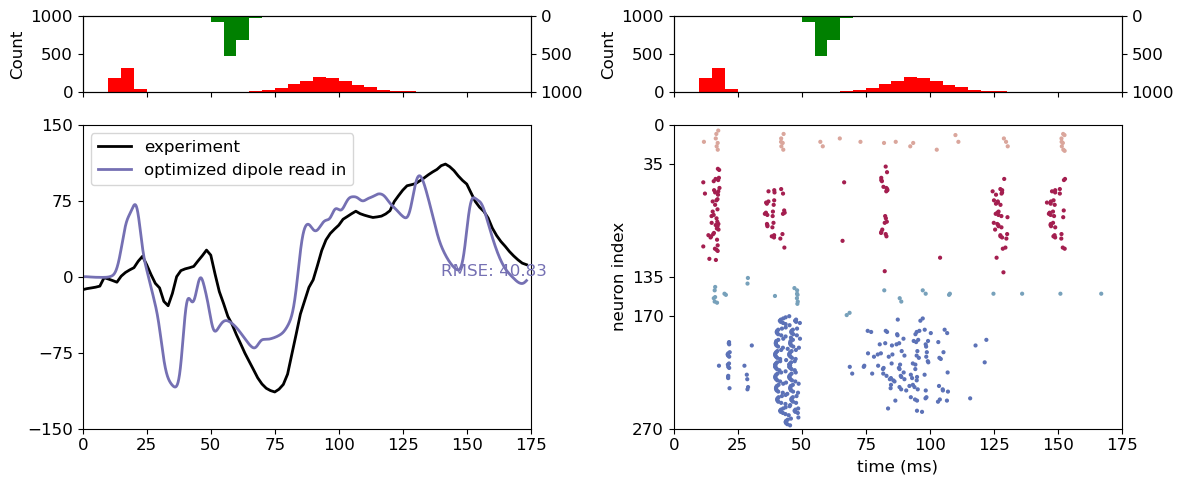

In [9]:
# there is still an issue with seeds but hopefully good enough as first pass

net = duecker_ET_model(params=params, add_drives_from_params=True)

#with MPIBackend(n_procs=n_procs):
opt_dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all')[0]


# for m in net.external_drives['evprox2']:
#     print(f'{m} {net.external_drives["evprox2"][m] == optim.net_.external_drives["prox2"][m]}')


opt_dpl.scale(scale_factor).smooth(smooth_window_len)

fig, ax = plt.subplots(2, 2,figsize=(12,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)


for i in range(2):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
#ax[1, 0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
ax[1, 0].plot(opt_dpl.times,opt_dpl.data['agg'], label='optimized dipole read in', color=col_lines[2], linewidth=2)

#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])
#ax[1, 0].text(140, 0.5, 'RMSE: %.2f' % _rmse(dpl_opt, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[1])
ax[1, 0].text(140, 0.5, 'RMSE: %.2f' % _rmse(opt_dpl, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[2])

ax[1, 0].legend()

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=4, alpha=1., c=colors)
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

fig.tight_layout()


In [12]:
net_no_ca = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca = net_block_ca(net_no_ca, perc=0.0)

#with MPIBackend(n_procs=n_procs):
noca_dpl = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]



noca_dpl.scale(scale_factor).smooth(smooth_window_len)



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying calcium model baseline correction


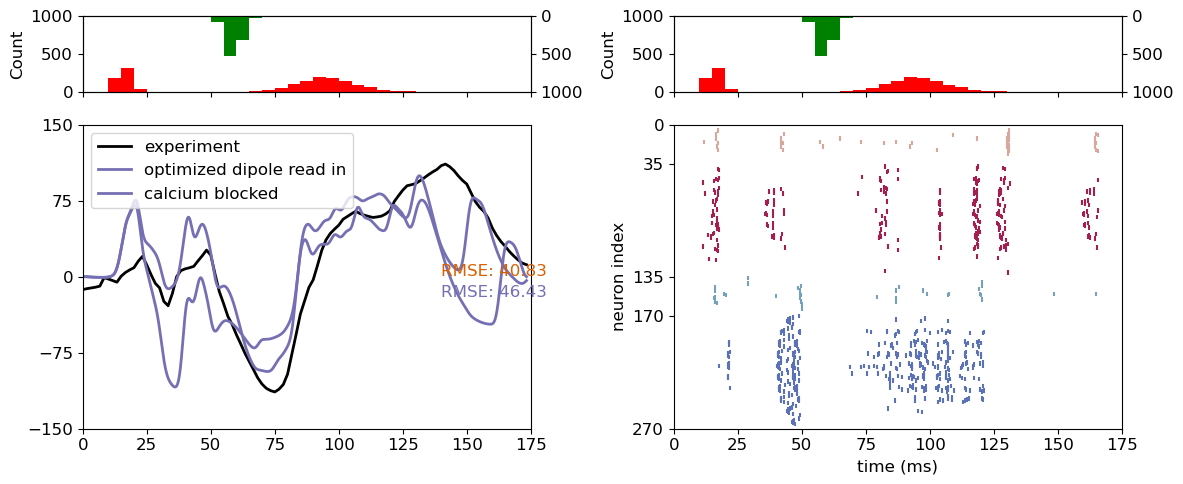

In [14]:
fig, ax = plt.subplots(2, 2,figsize=(12,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net_no_ca.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)


for i in range(2):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1, 0].plot(opt_dpl.times,opt_dpl.data['agg'], label='optimized dipole read in', color=col_lines[2], linewidth=2)
ax[1, 0].plot(noca_dpl.times,noca_dpl.data['agg'], label='calcium blocked', color=col_lines[2], linewidth=2)

#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])
ax[1, 0].text(140, 0.5, 'RMSE: %.2f' % _rmse(opt_dpl, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[1])
ax[1, 0].text(140, -20, 'RMSE: %.2f' % _rmse(noca_dpl, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[2])

ax[1, 0].legend()

# spiking
I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_blocked_L2_l5_new_NMDA.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_blocked_L2_l5_new_NMDA.pdf'), dpi=300)

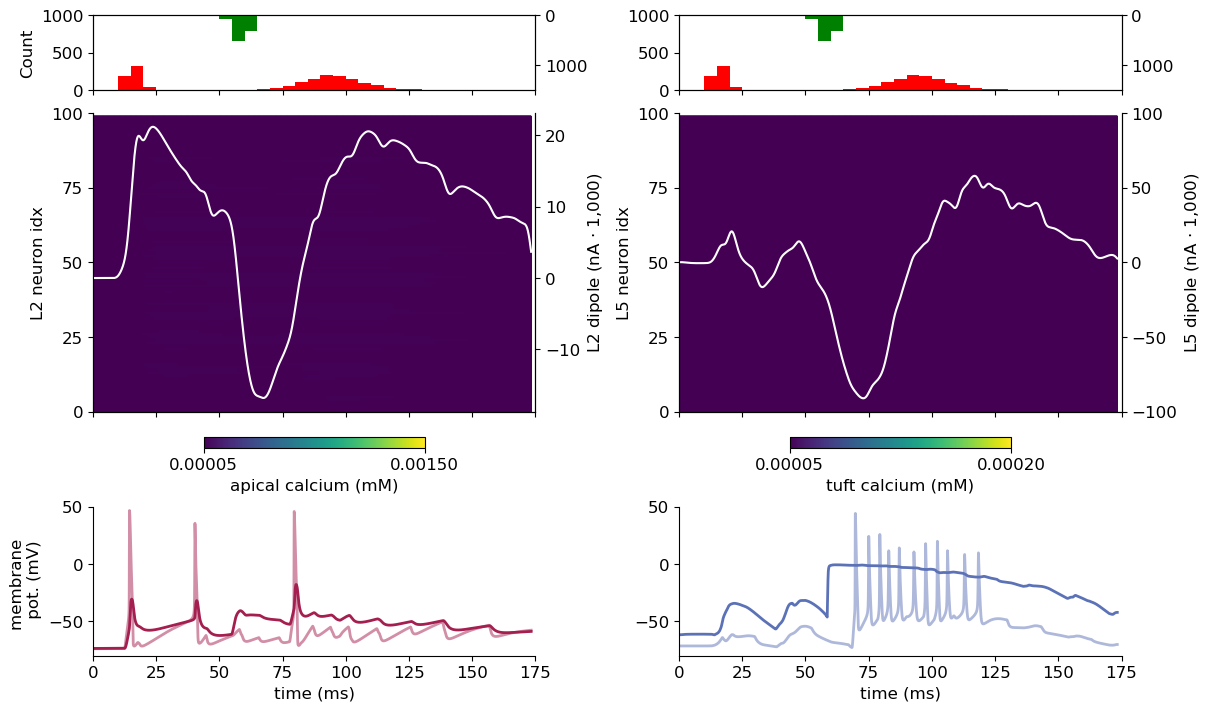

In [ ]:
l23_spiker = [gid for gid in net_no_ca.cell_response.spike_gids[0] if gid in net_no_ca.gid_ranges['L2_pyramidal']]
l5_spiker = [gid for gid in net_no_ca.cell_response.spike_gids[0] if gid in net_no_ca.gid_ranges['L5_pyramidal']]

l23_ca_apical_1 = np.zeros((100, len(net_no_ca.cell_response.ca[0][35]['soma'])))
for g, gid in enumerate(net_no_ca.gid_ranges['L2_pyramidal']):
    l23_ca_apical_1[g] = net_no_ca.cell_response.ca[0][gid]['apical_1']

l5_ca_apical_1 = np.zeros((100, len(net_no_ca.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net_no_ca.gid_ranges['L5_pyramidal']):
    l5_ca_apical_1[g] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']

fig, ax = plt.subplots(3,2,figsize=(12,7), height_ratios=[0.25,1, 0.5], sharex=True, constrained_layout=True)

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1000])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

im = ax[1,0].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l23_ca_apical_1, shading='gouraud', vmin=5e-5, vmax=0.0015, rasterized=True)
ax[1,0].set_ylim([0, 100])
ax[1,0].set_yticks(np.arange(0, 101, 25))
ax[1,0].spines['top'].set_visible(False)
ax[1,0].set_ylabel('L2 neuron idx')

ax10tw = ax[1,0].twinx()
ax10tw.plot(noca_dpl.times, noca_dpl.data['L2'], color='w')
ax10tw.spines['top'].set_visible(False)
ax10tw.set_ylabel('L2 dipole (nA $\cdot$ 1,000)')

cb = plt.colorbar(im, ax=ax[1,0], orientation='horizontal', shrink=0.5)
cb.set_ticks([5e-5, 0.0015])
cb.set_label('apical calcium (mM)')


im = ax[1,1].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l5_ca_apical_1, shading='gouraud', vmin=5e-5, vmax=0.0002, rasterized=True)
ax[1,1].set_ylim([0, 100])
ax[1,1].set_yticks(np.arange(0, 101, 25))
ax[1,1].spines['top'].set_visible(False)
ax[1,1].set_ylabel('L5 neuron idx')

ax11tw = ax[1,1].twinx()
ax11tw.set_ylim([-100, 100])
ax11tw.set_yticks(np.arange(-100, 101, 50))
ax11tw.plot(noca_dpl.times, noca_dpl.data['L5'], color='w')
ax11tw.spines['top'].set_visible(False)
ax11tw.set_ylabel('L5 dipole (nA $\cdot$ 1,000)')
cb = plt.colorbar(im, ax=ax[1,1], orientation='horizontal', shrink=0.5)
cb.set_ticks([5e-5, 0.0002])
cb.set_label('tuft calcium (mM)')


ax[2, 0].plot(net_no_ca.cell_response.times, net_no_ca.cell_response.vsec[0][l23_spiker[0]]['soma'], color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[2, 0].plot(net_no_ca.cell_response.times, net_no_ca.cell_response.vsec[0][l23_spiker[0]]['apical_1'], color=cm_neurons[1], linewidth=2)
ax[2, 0].set_ylim([-80, 50])
ax[2, 0].spines['top'].set_visible(False)
ax[2, 0].spines['right'].set_visible(False)
ax[2, 0].set_xlabel('time (ms)')
ax[2, 0].set_ylabel('membrane \n pot. (mV)')

ax[2, 1].plot(net_no_ca.cell_response.times, net_no_ca.cell_response.vsec[0][l5_spiker[22]]['soma'], color=cm_neurons[3], alpha=0.5, linewidth=2)
ax[2, 1].plot(net_no_ca.cell_response.times, net_no_ca.cell_response.vsec[0][l5_spiker[22]]['apical_tuft'], color=cm_neurons[3], linewidth=2)
ax[2, 1].set_ylim([-80, 50])
ax[2, 1].spines['top'].set_visible(False)
ax[2, 1].spines['right'].set_visible(False)
ax[2, 1].set_xlabel('time (ms)')
ax[2,1].set_xlim([0, 175])
ax[2,1].set_xticks(np.arange(0,176,25))
fig.savefig(os.path.join(pathfig, 'erp_noca_vsec.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_noca_vsec.pdf'), dpi=300)

In [ ]:
net_no_ca_l2 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l2 = net_block_ca(net_no_ca_l2, perc=0.0, cell_types=['L2_pyramidal'])

with MPIBackend(n_procs=n_procs):
    noca_dpl_l2 = simulate_dipole(net_no_ca_l2, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l2.scale(scale_factor).smooth(smooth_window_len)

net_no_ca_l5 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l5 = net_block_ca(net_no_ca_l5, perc=0.0, cell_types=['L5_pyramidal'])
with MPIBackend(n_procs=n_procs):
    noca_dpl_l5 = simulate_dipole(net_no_ca_l5, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l5.scale(scale_factor).smooth(smooth_window_len)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

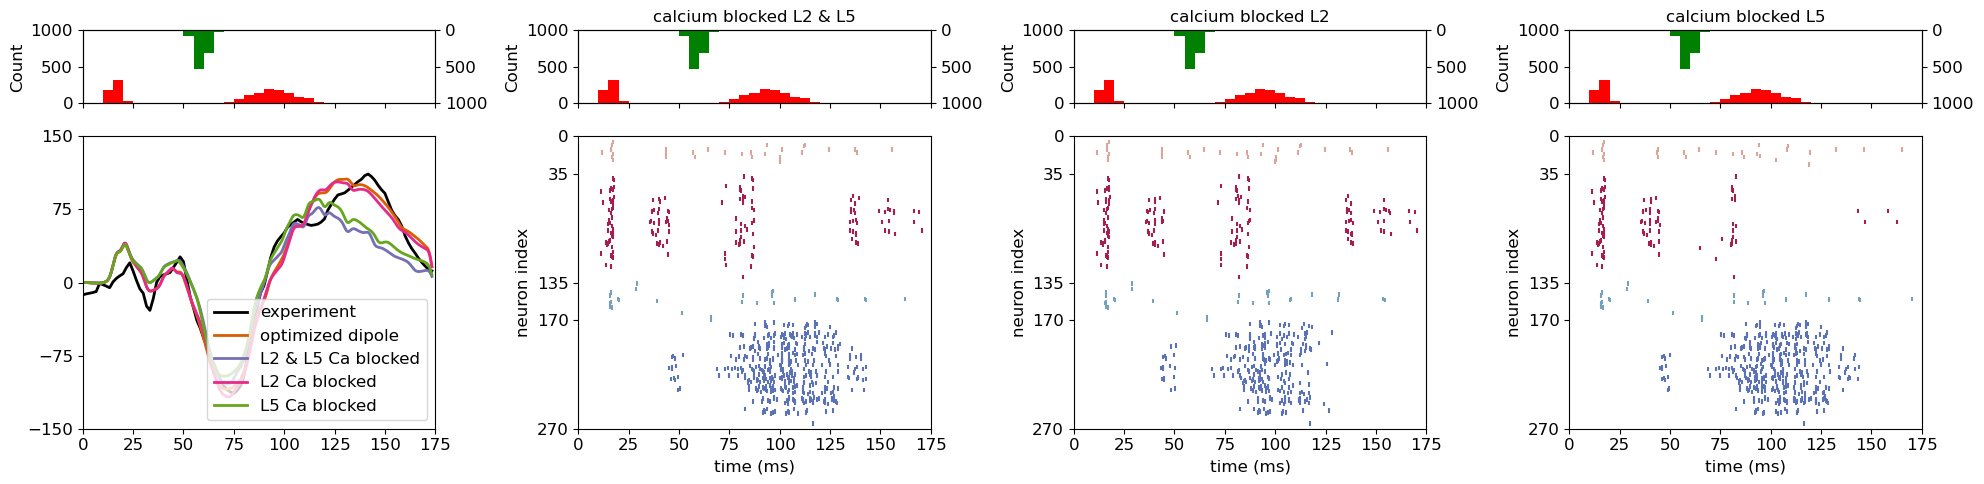

In [ ]:
fig, ax = plt.subplots(2, 4,figsize=(20,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net_no_ca.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)


for i in range(4):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1, 0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
ax[1, 0].plot(noca_dpl.times,noca_dpl.data['agg'], label='L2 & L5 Ca blocked', color=col_lines[2], linewidth=2)
ax[1, 0].plot(noca_dpl_l2.times,noca_dpl_l2.data['agg'], label='L2 Ca blocked', color=col_lines[3], linewidth=2)
ax[1, 0].plot(noca_dpl_l5.times,noca_dpl_l5.data['agg'], label='L5 Ca blocked', color=col_lines[4], linewidth=2)

#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])

ax[1, 0].legend()

# spiking
I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

# spiking l2 blocked
I = np.array(net_no_ca_l2.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l2.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l2.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca_l2, gid) for gid in gids]

ax[1, 2].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 2].set_ylabel('neuron index')
ax[1, 2].set_xlim([0, 175])
ax[1, 2].set_xlabel('time (ms)')
ax[1, 2].set_ylim([0, 270])
ax[1, 2].set_yticks([0, 35, 135, 170, 270])
ax[1, 2].invert_yaxis()
ax[1, 2].set_xticks(np.arange(0, 176, 25))
ax[1, 2].set_xlim((0, 175))

# spiking l5 blocked
I = np.array(net_no_ca_l5.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l5.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l5.cell_response.spike_times).reshape(-1,)[I]    

colors = [assign_color(net_no_ca_l5, gid) for gid in gids]

ax[1, 3].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 3].set_ylabel('neuron index')
ax[1, 3].set_xlim([0, 175])
ax[1, 3].set_xlabel('time (ms)')        
ax[1, 3].set_ylim([0, 270])
ax[1, 3].set_yticks([0, 35, 135, 170, 270])
ax[1, 3].invert_yaxis()
ax[1, 3].set_xticks(np.arange(0, 176, 25))
ax[1, 3].set_xlim((0, 175))

ax[0, 1].set_title('calcium blocked L2 & L5')
ax[0, 2].set_title('calcium blocked L2')
ax[0, 3].set_title('calcium blocked L5')

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_blocked.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_blocked.pdf'), dpi=300)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

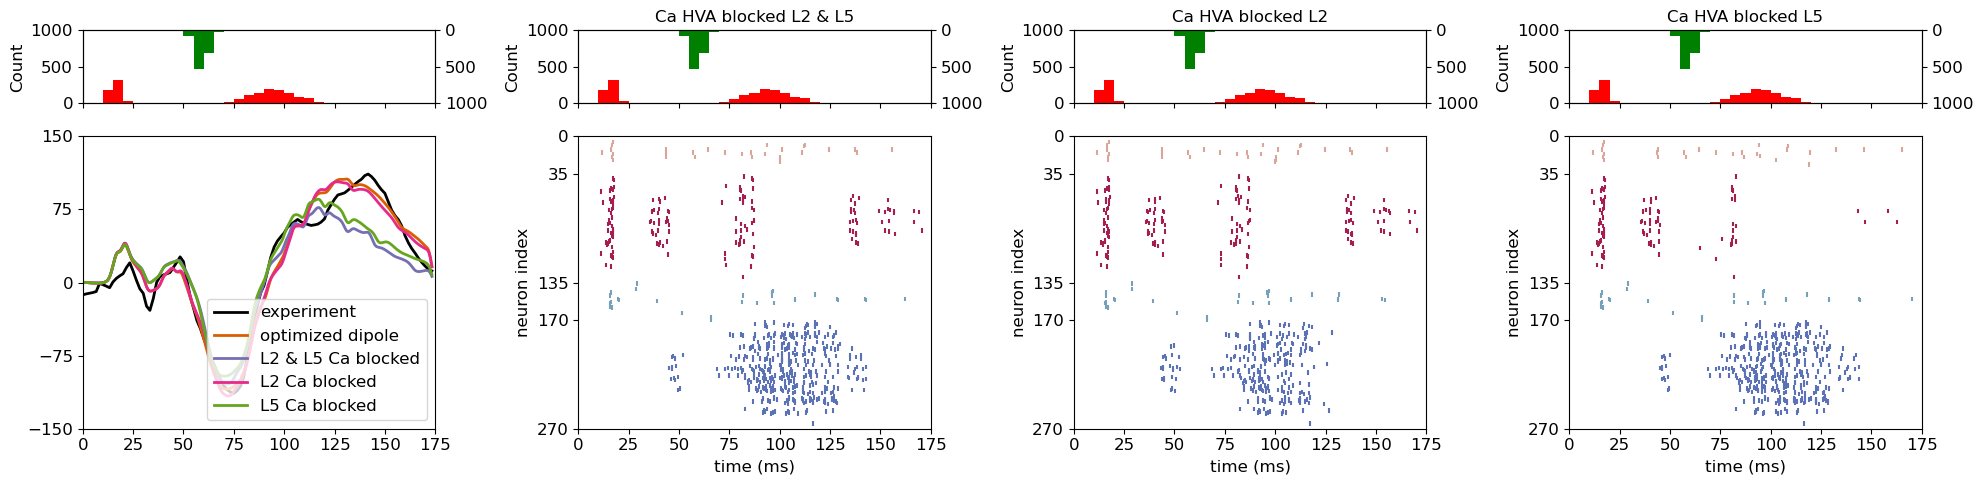

In [ ]:
net_no_ca = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca = net_block_ca(net_no_ca, perc=0.0, which_chan=['hva'])

with MPIBackend(n_procs=n_procs):
    noca_dpl = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]



noca_dpl.scale(scale_factor).smooth(smooth_window_len)

net_no_ca_l2 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l2 = net_block_ca(net_no_ca_l2, perc=0.0, cell_types=['L2_pyramidal'], which_chan=['hva'])

with MPIBackend(n_procs=n_procs):
    noca_dpl_l2 = simulate_dipole(net_no_ca_l2, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l2.scale(scale_factor).smooth(smooth_window_len)

net_no_ca_l5 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l5 = net_block_ca(net_no_ca_l5, perc=0.0, cell_types=['L5_pyramidal'], which_chan=['hva'])
with MPIBackend(n_procs=n_procs):
    noca_dpl_l5 = simulate_dipole(net_no_ca_l5, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l5.scale(scale_factor).smooth(smooth_window_len)


fig, ax = plt.subplots(2, 4,figsize=(20,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net_no_ca.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)


for i in range(4):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1, 0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
ax[1, 0].plot(noca_dpl.times,noca_dpl.data['agg'], label='L2 & L5 Ca blocked', color=col_lines[2], linewidth=2)
ax[1, 0].plot(noca_dpl_l2.times,noca_dpl_l2.data['agg'], label='L2 Ca blocked', color=col_lines[3], linewidth=2)
ax[1, 0].plot(noca_dpl_l5.times,noca_dpl_l5.data['agg'], label='L5 Ca blocked', color=col_lines[4], linewidth=2)

#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])

ax[1, 0].legend()

# spiking
I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

# spiking l2 blocked
I = np.array(net_no_ca_l2.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l2.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l2.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca_l2, gid) for gid in gids]

ax[1, 2].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 2].set_ylabel('neuron index')
ax[1, 2].set_xlim([0, 175])
ax[1, 2].set_xlabel('time (ms)')
ax[1, 2].set_ylim([0, 270])
ax[1, 2].set_yticks([0, 35, 135, 170, 270])
ax[1, 2].invert_yaxis()
ax[1, 2].set_xticks(np.arange(0, 176, 25))
ax[1, 2].set_xlim((0, 175))

# spiking l5 blocked
I = np.array(net_no_ca_l5.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l5.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l5.cell_response.spike_times).reshape(-1,)[I]    

colors = [assign_color(net_no_ca_l5, gid) for gid in gids]

ax[1, 3].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 3].set_ylabel('neuron index')
ax[1, 3].set_xlim([0, 175])
ax[1, 3].set_xlabel('time (ms)')        
ax[1, 3].set_ylim([0, 270])
ax[1, 3].set_yticks([0, 35, 135, 170, 270])
ax[1, 3].invert_yaxis()
ax[1, 3].set_xticks(np.arange(0, 176, 25))
ax[1, 3].set_xlim((0, 175))

ax[0, 1].set_title('Ca HVA blocked L2 & L5')
ax[0, 2].set_title('Ca HVA blocked L2')
ax[0, 3].set_title('Ca HVA blocked L5')

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_block_hva.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_block_hva.pdf'), dpi=300)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

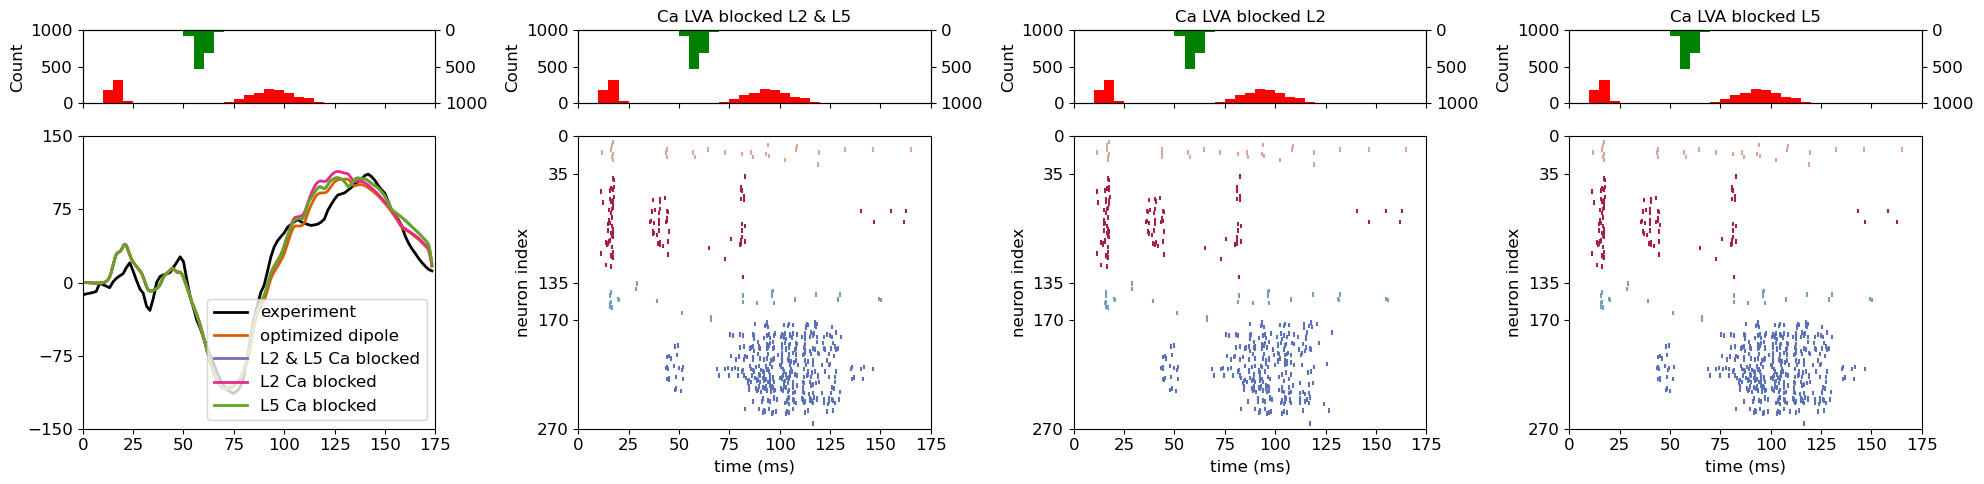

In [ ]:
net_no_ca = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca = net_block_ca(net_no_ca, perc=0.0, which_chan=['lva'])

with MPIBackend(n_procs=n_procs):
    noca_dpl = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]



noca_dpl.scale(scale_factor).smooth(smooth_window_len)

net_no_ca_l2 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l2 = net_block_ca(net_no_ca_l2, perc=0.0, cell_types=['L2_pyramidal'], which_chan=['lva'])

with MPIBackend(n_procs=n_procs):
    noca_dpl_l2 = simulate_dipole(net_no_ca_l2, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l2.scale(scale_factor).smooth(smooth_window_len)

net_no_ca_l5 = duecker_ET_model(params=params, add_drives_from_params=True)
net_no_ca_l5 = net_block_ca(net_no_ca_l5, perc=0.0, cell_types=['L5_pyramidal'], which_chan=['lva'])
with MPIBackend(n_procs=n_procs):
    noca_dpl_l5 = simulate_dipole(net_no_ca_l5, tstop=tstop, n_trials=1,bsl_cor='duecker', record_ca='all', record_vsec='all')[0]
noca_dpl_l5.scale(scale_factor).smooth(smooth_window_len)


fig, ax = plt.subplots(2, 4,figsize=(20,5), height_ratios=[0.25, 1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net_no_ca.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net_no_ca.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)


for i in range(4):
    ax[0, i].hist(spike_prox1, bins, color='r')
    ax[0, i].set_ylim([0, 1000])
    ax[0, i].set_ylabel('Count')
    ax[0, i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0, i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1000])
    ax1tw.invert_yaxis()


ax[1, 0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
#ax[1, 0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1, 0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
ax[1, 0].plot(noca_dpl.times,noca_dpl.data['agg'], label='L2 & L5 Ca blocked', color=col_lines[2], linewidth=2)
ax[1, 0].plot(noca_dpl_l2.times,noca_dpl_l2.data['agg'], label='L2 Ca blocked', color=col_lines[3], linewidth=2)
ax[1, 0].plot(noca_dpl_l5.times,noca_dpl_l5.data['agg'], label='L5 Ca blocked', color=col_lines[4], linewidth=2)

#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1, 0].set_ylim([-150, 150])
ax[1, 0].set_yticks([-150, -75, 0, 75, 150])

ax[1, 0].legend()

# spiking
I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]

ax[1, 1].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 1].set_ylabel('neuron index')
ax[1, 1].set_xlim([0, 175])
ax[1, 1].set_xlabel('time (ms)')
ax[1, 1].set_ylim([0, 270])
ax[1, 1].set_yticks([0, 35, 135, 170, 270])
ax[1, 1].invert_yaxis()
ax[1, 1].set_xticks(np.arange(0, 176, 25))
ax[1, 1].set_xlim((0, 175))

# spiking l2 blocked
I = np.array(net_no_ca_l2.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l2.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l2.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca_l2, gid) for gid in gids]

ax[1, 2].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 2].set_ylabel('neuron index')
ax[1, 2].set_xlim([0, 175])
ax[1, 2].set_xlabel('time (ms)')
ax[1, 2].set_ylim([0, 270])
ax[1, 2].set_yticks([0, 35, 135, 170, 270])
ax[1, 2].invert_yaxis()
ax[1, 2].set_xticks(np.arange(0, 176, 25))
ax[1, 2].set_xlim((0, 175))

# spiking l5 blocked
I = np.array(net_no_ca_l5.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca_l5.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca_l5.cell_response.spike_times).reshape(-1,)[I]    

colors = [assign_color(net_no_ca_l5, gid) for gid in gids]

ax[1, 3].scatter(times, gids, s=10, alpha=1., c=colors, marker='|')
ax[1, 3].set_ylabel('neuron index')
ax[1, 3].set_xlim([0, 175])
ax[1, 3].set_xlabel('time (ms)')        
ax[1, 3].set_ylim([0, 270])
ax[1, 3].set_yticks([0, 35, 135, 170, 270])
ax[1, 3].invert_yaxis()
ax[1, 3].set_xticks(np.arange(0, 176, 25))
ax[1, 3].set_xlim((0, 175))

ax[0, 1].set_title('Ca LVA blocked L2 & L5')
ax[0, 2].set_title('Ca LVA blocked L2')
ax[0, 3].set_title('Ca LVA blocked L5')

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_block_lva.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'erp_spiking_ca_block_lva.pdf'), dpi=300)